# From walking to parkour: building the environment

In notebook 1 you trained a Go2 to walk on flat ground. This notebook builds on that to to get the Go2 to do something
much harder: **climbing up walls, jumping down from boxes and jumping across gaps**.

The training itself is one command. What decides whether you get a parkour robot or one that stands still
(or face-plants) is the **environment design**, and that is what this notebook is about:

| Part | Topic | You will |
|---|---|---|
| 0 | Setup | |
| 1 | What changes from walking to parkour | compare the two MDPs |
| 2 | **Terrain** | generate obstacle grids, write your own obstacle type |
| 3 | **Task code** | write a termination, a reward, an observation fix; package and register the task |
| 4 | **Look before you train** | put robots in front of obstacles, see what they perceive, test every new term |
| 5 | **Curriculum** + sanity training | train for a minute, check the curriculum moves |
| 6 | **Evaluation** | a success-rate map per obstacle and difficulty |
| 7 | The real training (done on the terminal, ~1 h) | train, monitor, evaluate, drive the result |
| 8 | Recap and test questions | |

Everything you write here goes into a Python package, `parkour/go2_parkour/`, through `%%writefile` cells: the
code you read is exactly the code that the training command runs. (So edit the package *in the notebook*: running
a `%%writefile` cell overwrites the file with the cell's content.)

> Start Jupyter with `./start_jupyter.sh` from the repository folder: it makes the `go2_parkour` package importable.
> Compute: about 5 minutes for the whole notebook; the real training (Part 7) runs in a terminal.

---
# Part 0 — Setup

The same helpers as in notebook 1 (quiet simulator logs, videos), plus `reload_parkour()`: after a `%%writefile`
cell changes a file of the package, it re-imports the package so the new code is used.

In [ ]:
import copy
import importlib
import inspect
import math
import os
import sys
from contextlib import contextmanager, redirect_stderr, redirect_stdout
from pathlib import Path
from tempfile import TemporaryFile

import warp as wp

wp.config.enable_backward = False  # no differentiable physics needed; saves compile time
os.environ.pop("DISPLAY", None)  # no viewer windows: we use simulated cameras

import imageio.v2 as imageio
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Video, display
from wurlitzer import STDOUT, pipes

# the repository folder: the first folder (from here upwards) that contains the parkour package
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "parkour" / "go2_parkour").is_dir()), None)
assert ROOT is not None, "Run this notebook inside the repository, with Jupyter started by ./start_jupyter.sh."
os.chdir(ROOT)  # so relative paths (%%writefile parkour/..., logs/, videos/) work wherever the notebook is
(ROOT / "videos").mkdir(exist_ok=True)
SIM_ARGS = {"visualizer": None, "visualizer_explicit": True}  # headless


@contextmanager
def quiet_simulation():
    # Hide Python *and* C++ simulator logs; print them if the block raises an error.
    with TemporaryFile(mode="w+", encoding="utf-8") as logs:
        try:
            with redirect_stdout(logs), redirect_stderr(logs), pipes(stdout=logs, stderr=STDOUT):
                yield
        except BaseException:
            logs.seek(0)
            print(logs.read()[-20000:], end="")
            raise


def save_video(frames, name, fps=25, width=640):
    path = ROOT / "videos" / f"{name}.mp4"
    imageio.mimsave(path, frames, fps=fps, macro_block_size=1)
    display(Video(str(path), embed=True, width=width, html_attributes="controls loop muted autoplay playsinline"))
    return path.relative_to(ROOT)


def reload_parkour():
    # Re-import the package files (in dependency order) after a %%writefile cell changed one of them.
    for name in ("terrains", "mdp", "env_cfg", "agents", "evaluation"):
        module = sys.modules.get(f"go2_parkour.{name}")
        if module is not None:
            importlib.reload(module)


import go2_parkour  # registers the Go2-Parkour task with gymnasium

print(f"GPU: {torch.cuda.get_device_name(0)} | parkour package: {Path(go2_parkour.__file__).parent.relative_to(ROOT)}")

---
# Part 1 — What changes from walking to parkour

We don't start from scratch: Isaac Lab's **Go2 rough-terrain task** (`Isaac-Velocity-Rough-UnitreeGo2`) already
has most of what we need. Our task inherits it and changes only what parkour requires:

| | Notebook 1: flat walking | Rough-terrain task (inherited) | **Our parkour task** |
|---|---|---|---|
| Terrain | plane | stairs, slopes, random boxes | **walls to climb, drops, gaps, gap + step** |
| Observations (policy input) | 48 | 48 + **187 height-scan values** | 235, with a **fixed** height scan (Part 4) |
| Commands | random velocity | random velocity | **mostly forward** (into the obstacles) |
| Terminations | time-out, trunk contact | same | + **fell into a gap** |
| Rewards | velocity tracking + regularizers | same, + base height | + **feet stumbling** into walls |
| Curriculum | none | terrain levels | terrain levels (Part 5) |
| Network | [128, 128, 128] | [512, 256, 128] | [512, 256, 128] |
| Training | 1000 iterations | 1500 | **3000** (~1 h) |

**Why a height scan and not a camera?** A height scan (a grid of terrain heights around the robot) is the simplest
way to give a policy "vision" of the terrain. Published parkour work uses depth cameras, usually by first training a
*teacher* policy with exactly this kind of privileged height information, then distilling it into a camera-based
*student* (Part 8). The teacher comes first, and that is what we build.

---
# Part 2 — Terrain

## 2.1 How Isaac Lab builds terrain

The **terrain generator** (`TerrainGeneratorCfg`) builds one big mesh out of square **tiles** (sub-terrains),
arranged in a grid. We will arrange the terrain according to the following:

- **columns = obstacle types**: each type gets a share of the columns of tiles given by its `proportion`,
- **rows = difficulty levels**: the higher the row, the bigger the obstacle (details below),
- each robot spawns at the **origin** of one tile (its centre), and the curriculum moves it between rows.

**What is a "difficulty"?** A number between **0** (easiest) and **1** (hardest) that the generator passes to the
obstacle's function. The function turns it into a size by interpolating its range. For example, the wall height of
a *climb* tile, with `pit_depth_range = (0.05, 0.30)`:

$$\text{wall height} = 0.05 + \text{difficulty} \times (0.30 - 0.05)$$

so difficulty 0 gives a 5 cm wall, 0.5 gives 17.5 cm, 1 gives 30 cm.

With `curriculum=True`, the difficulty comes from the tile's **row**: with $N = 10$ rows numbered $r = 0, \dots, 9$,
row $r$ gets a difficulty drawn randomly between $r/N$ and $(r+1)/N$. Row 0 gets 0.0-0.1, row 2 gets 0.2-0.3,
row 9 gets 0.9-1.0. (The small random part makes the several columns of one type slightly different from each other.)
So on a climb tile in row 2 the wall is 10-12.5 cm high.

Think of the ground as a **chessboard of 8 m x 8 m tiles**, each with one obstacle around a central spawn platform.
Going along a row, the *type* of obstacle changes; going up a column, the *same* obstacle gets bigger. A robot keeps
its column (obstacle type) its whole life; the curriculum only moves it up and down its column:

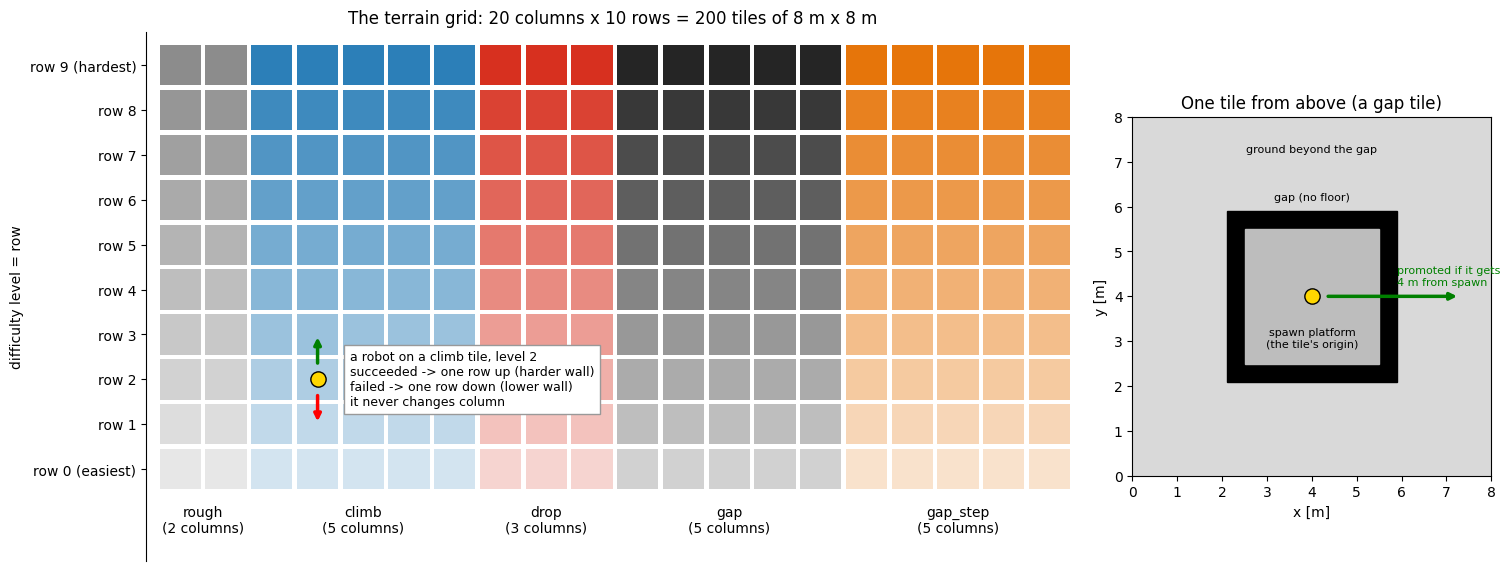

In [4]:
import matplotlib.patches as patches

# the 20 columns of our parkour grid, shared out by `proportion` (see PARKOUR_TERRAINS_CFG in 2.2)
TYPES = [("rough", 2, "#8c8c8c"), ("climb", 5, "#2c7fb8"), ("drop", 3, "#d7301f"), ("gap", 5, "#252525"),
         ("gap_step", 5, "#e6750a")]
fig, (ax, ax_tile) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [2.6, 1]}, layout="constrained")

col = 0
for name, n_cols, color in TYPES:
    for c in range(col, col + n_cols):
        for r in range(10):  # darker = harder
            ax.add_patch(patches.Rectangle((c, r), 0.9, 0.9, color=color, alpha=0.12 + 0.88 * (r + 1) / 10, lw=0))
    ax.text(col + n_cols / 2 - 0.05, -0.35, f"{name}\n({n_cols} columns)", ha="center", va="top", fontsize=10)
    col += n_cols
ax.set(xlim=(-0.3, 20.1), ylim=(-1.6, 10.2), xticks=[], title="The terrain grid: 20 columns x 10 rows = 200 tiles of 8 m x 8 m")
ax.set_yticks(np.arange(10) + 0.45, ["row 0 (easiest)"] + [f"row {r}" for r in range(1, 9)] + ["row 9 (hardest)"])
ax.set_ylabel("difficulty level = row")
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
# one robot in a climb column, moved by the curriculum
x, y = 3.45, 2.45
ax.plot(x, y, "o", ms=11, color="gold", mec="black", zorder=3)
ax.annotate("", xy=(x, y + 1.0), xytext=(x, y + 0.3), arrowprops=dict(arrowstyle="-|>", lw=2.5, color="green"))
ax.annotate("", xy=(x, y - 1.0), xytext=(x, y - 0.3), arrowprops=dict(arrowstyle="-|>", lw=2.5, color="red"))
ax.text(x + 0.7, y, "a robot on a climb tile, level 2\nsucceeded -> one row up (harder wall)\nfailed -> one row down (lower wall)\n"
        "it never changes column", va="center", fontsize=9, bbox=dict(fc="white", ec="0.6"))

# one tile seen from above: a gap tile
gap = 0.4
ax_tile.add_patch(patches.Rectangle((0, 0), 8, 8, color="#d9d9d9"))
ax_tile.add_patch(patches.Rectangle((2.5 - gap, 2.5 - gap), 3 + 2 * gap, 3 + 2 * gap, color="black"))
ax_tile.add_patch(patches.Rectangle((2.5, 2.5), 3, 3, color="#bdbdbd"))
ax_tile.plot(4, 4, "o", ms=11, color="gold", mec="black")
ax_tile.annotate("", xy=(7.3, 4), xytext=(4.3, 4), arrowprops=dict(arrowstyle="-|>", lw=2.5, color="green"))
ax_tile.text(4, 3.3, "spawn platform\n(the tile's origin)", ha="center", va="top", fontsize=8)
ax_tile.text(4, 6.15, "gap (no floor)", ha="center", fontsize=8, color="black")
ax_tile.text(4, 7.2, "ground beyond the gap", ha="center", fontsize=8)
ax_tile.text(5.9, 4.25, "promoted if it gets\n4 m from spawn", fontsize=8, color="green")
ax_tile.set(xlim=(0, 8), ylim=(0, 8), aspect="equal", xlabel="x [m]", ylabel="y [m]", title="One tile from above (a gap tile)")
plt.show()

A sub-terrain type is just a **function**: `(difficulty, cfg) -> (list of meshes, spawn origin)`, plus a config
class that points to it. Here is Isaac Lab's gap terrain, which we will use as is:

In [5]:
from isaaclab.terrains.trimesh import mesh_terrains

print(inspect.getsource(mesh_terrains.gap_terrain))

def gap_terrain(
    difficulty: float, cfg: mesh_terrains_cfg.MeshGapTerrainCfg
) -> tuple[list[trimesh.Trimesh], np.ndarray]:
    """Generate a terrain with a gap around the platform.

    The terrain has a ground with a platform in the middle. The platform is surrounded by a gap
    of width :obj:`gap_width` on all sides.

    .. image:: ../../_static/terrains/trimesh/gap_terrain.jpg
       :width: 40%
       :align: center

    Args:
        difficulty: The difficulty of the terrain. This is a value between 0 and 1.
        cfg: The configuration for the terrain.

    Returns:
        A tuple containing the tri-mesh of the terrain and the origin of the terrain (in m).
    """
    # resolve the terrain configuration
    gap_width = cfg.gap_width_range[0] + difficulty * (cfg.gap_width_range[1] - cfg.gap_width_range[0])

    # initialize list of meshes
    meshes_list = list()
    # constants for terrain generation
    terrain_height = 1.0
    terrain_center = (0.5 * cfg.size[0], 0.5 

Notice the gap has **no floor**: only the platform and the outer ring are meshes. Keep that in mind for Part 3.

## 2.2 Your own obstacle: a gap onto higher ground

Isaac Lab has walls (a *pit* the robot spawns in), drops (a *box* it spawns on) and gaps. We add a harder,
combined obstacle: **jump across a gap *and* up a step simultaneously**. The function builds two `trimesh` boxes: the platform,
and a ring (`make_border`) whose top is raised by the step height. Both sizes grow with `difficulty`.

The same file defines the whole terrain grid, `PARKOUR_TERRAINS_CFG`: 10 levels x 20 columns of 8 m tiles. Read the
ranges: they set the hardest obstacle of each type (a 30 cm wall is about the height of the Go2's hips).

In [6]:
%%writefile parkour/go2_parkour/terrains.py
"""Parkour terrains: a custom "gap + step up" sub-terrain and the terrain generator config of the task."""

from __future__ import annotations

import numpy as np
import trimesh

import isaaclab.terrains as terrain_gen
from isaaclab.terrains import SubTerrainBaseCfg, TerrainGeneratorCfg
from isaaclab.terrains.trimesh.utils import make_border
from isaaclab.utils import configclass


def gap_step_terrain(difficulty: float, cfg: GapStepTerrainCfg) -> tuple[list[trimesh.Trimesh], np.ndarray]:
    """A platform surrounded by a gap; the ground beyond the gap is raised by a step.

    The robot spawns on the platform and must jump across the gap *and* up the step.
    Both the gap width and the step height grow linearly with ``difficulty`` (0 = easiest, 1 = hardest).
    Like Isaac Lab's own gap terrain, the gap has no floor: a robot that falls in keeps falling.

    Returns the meshes (the terrain spans x in [0, size_x], y in [0, size_y]) and the spawn origin.
    """
    gap = cfg.gap_width_range[0] + difficulty * (cfg.gap_width_range[1] - cfg.gap_width_range[0])
    step = cfg.step_height_range[0] + difficulty * (cfg.step_height_range[1] - cfg.step_height_range[0])
    thickness = 1.0  # how far the solid blocks extend below their top surface
    cx, cy = 0.5 * cfg.size[0], 0.5 * cfg.size[1]

    # central platform, top surface at z = 0
    platform = trimesh.creation.box(
        (cfg.platform_width, cfg.platform_width, thickness),
        trimesh.transformations.translation_matrix((cx, cy, -thickness / 2)),
    )
    # outer ring beyond the gap, top surface at z = step
    inner = cfg.platform_width + 2 * gap
    ring = make_border(cfg.size, (inner, inner), thickness + step, (cx, cy, step - (thickness + step) / 2))
    return [platform, *ring], np.array([cx, cy, 0.0])


@configclass
class GapStepTerrainCfg(SubTerrainBaseCfg):
    """Configuration for :func:`gap_step_terrain`."""

    function = gap_step_terrain
    gap_width_range: tuple[float, float] = (0.05, 0.35)
    """Gap width [m] at difficulty 0 and 1."""
    step_height_range: tuple[float, float] = (0.0, 0.15)
    """Height [m] of the far side above the platform at difficulty 0 and 1."""
    platform_width: float = 3.0
    """Side length [m] of the square spawn platform."""


PARKOUR_TERRAINS_CFG = TerrainGeneratorCfg(
    size=(8.0, 8.0),  # each tile is 8 m x 8 m
    border_width=20.0,  # flat border around the whole grid
    num_rows=10,  # rows = difficulty levels (with the curriculum)
    num_cols=20,  # columns = obstacle types, split by `proportion`
    horizontal_scale=0.1,
    vertical_scale=0.005,
    slope_threshold=0.75,
    use_cache=False,
    sub_terrains={
        # warm-up: mildly uneven ground
        "rough": terrain_gen.HfRandomUniformTerrainCfg(
            proportion=0.1, noise_range=(0.01, 0.06), noise_step=0.01, border_width=0.25
        ),
        # spawn at the bottom of a pit, climb the wall to get out
        "climb": terrain_gen.MeshPitTerrainCfg(proportion=0.25, pit_depth_range=(0.05, 0.30), platform_width=3.0),
        # spawn on top of a box, step or jump down
        "drop": terrain_gen.MeshBoxTerrainCfg(proportion=0.15, box_height_range=(0.05, 0.40), platform_width=3.0),
        # spawn on a platform surrounded by a gap, jump across
        "gap": terrain_gen.MeshGapTerrainCfg(proportion=0.25, gap_width_range=(0.05, 0.45), platform_width=3.0),
        # our own: jump across a gap onto higher ground
        "gap_step": GapStepTerrainCfg(proportion=0.25),
    },
)
"""The parkour terrain grid: 10 difficulty levels x 20 columns of obstacle types."""

Overwriting parkour/go2_parkour/terrains.py


## 2.3 Look at it, without a simulator

The generator is plain Python: it runs in a fraction of a second, no simulation needed. To see the result we
ray-cast the mesh from above on a 5 cm grid (with NVIDIA Warp, the same tool the robot's height scanner uses) and
plot the height. For the picture we use **one column per type** (equal proportions).

**Predict first:** in which colour will the gaps show up? (Hint: what does a ray that hits nothing return?)

[INFO] Generating terrains based on curriculum took Last: 0.107699 s


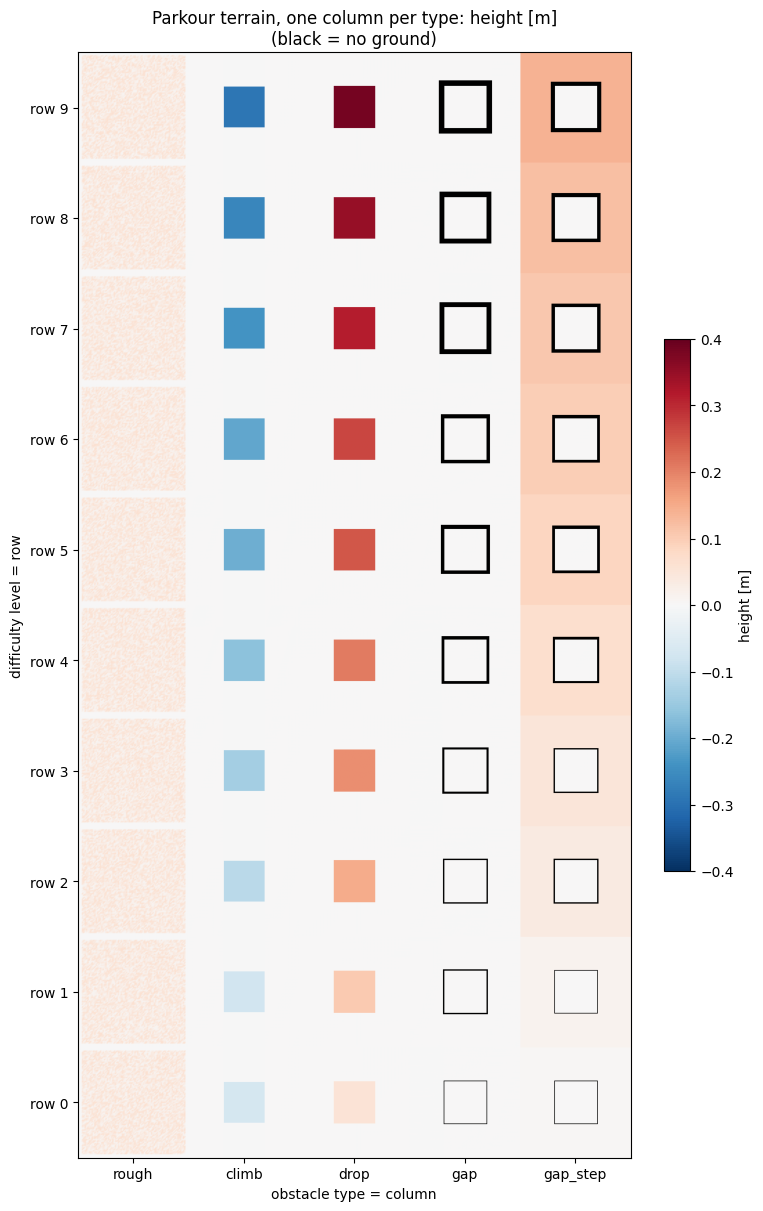

spawn heights [m], one row per type (levels 0..9):
  rough     [0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06 0.06]
  climb     [-0.07 -0.08 -0.11 -0.14 -0.16 -0.19 -0.21 -0.24 -0.26 -0.29]
  drop      [0.05 0.1  0.15 0.19 0.21 0.25 0.27 0.32 0.35 0.38]
  gap       [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  gap_step  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [7]:
from isaaclab.terrains import TerrainGenerator
from isaaclab.utils.warp import convert_to_warp_mesh, raycast_mesh

reload_parkour()
from go2_parkour.terrains import PARKOUR_TERRAINS_CFG


def one_column_per_type(gen_cfg):
    cfg = copy.deepcopy(gen_cfg)
    cfg.curriculum, cfg.border_width, cfg.num_cols = True, 0.0, len(cfg.sub_terrains)
    for sub in cfg.sub_terrains.values():
        sub.proportion = 1.0
    return cfg


def height_map(mesh, resolution=0.05):
    # Cast rays straight down onto the mesh; returns heights (NaN where nothing was hit) and the plot extent.
    lo, hi = mesh.bounds
    xs = torch.arange(lo[0], hi[0], resolution, device="cuda")
    ys = torch.arange(lo[1], hi[1], resolution, device="cuda")
    gx, gy = torch.meshgrid(xs, ys, indexing="xy")
    starts = torch.stack([gx, gy, torch.full_like(gx, 10.0)], dim=-1).reshape(1, -1, 3)
    directions = torch.zeros_like(starts)
    directions[..., 2] = -1.0
    hits = raycast_mesh(starts, directions, convert_to_warp_mesh(mesh.vertices, mesh.faces, device="cuda"))[0]
    z = hits[0, :, 2].reshape(gx.shape).cpu().numpy()
    return np.where(np.isfinite(z), z, np.nan), (lo[0], hi[0], lo[1], hi[1])


preview = one_column_per_type(PARKOUR_TERRAINS_CFG)
generator = TerrainGenerator(preview, device="cuda")
heights, extent = height_map(generator.terrain_mesh)

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("black")  # rays that hit nothing
# Isaac Lab lays the rows out along the world's x axis; we transpose so that, like in the diagram of 2.1,
# rows (difficulty) go up and columns (obstacle types) go across
fig, ax = plt.subplots(figsize=(8, 12), layout="constrained")
im = ax.imshow(heights.T, origin="lower", extent=(extent[2], extent[3], extent[0], extent[1]), cmap=cmap, vmin=-0.4, vmax=0.4)
size = preview.size[0]
ax.set_xticks(extent[2] + size * (np.arange(preview.num_cols) + 0.5), list(preview.sub_terrains))
ax.set_yticks(extent[0] + size * (np.arange(preview.num_rows) + 0.5), [f"row {i}" for i in range(preview.num_rows)])
ax.set(xlabel="obstacle type = column", ylabel="difficulty level = row",
       title="Parkour terrain, one column per type: height [m]\n(black = no ground)")
fig.colorbar(im, ax=ax, fraction=0.04, label="height [m]")
plt.show()
print("spawn heights [m], one row per type (levels 0..9):")
for name, z in zip(preview.sub_terrains, generator.terrain_origins[:, :, 2].T):
    print(f"  {name:9s}", np.round(z, 2))

What to see: the pits (*climb*) are blue (the robot spawns at the bottom), the boxes (*drop*) are red, the gaps
are black and widen with the level, and in *gap_step* the far side gets redder (higher) as the gap widens.

Now a cross-section of your own obstacle at three difficulties, through the centre of the tile:

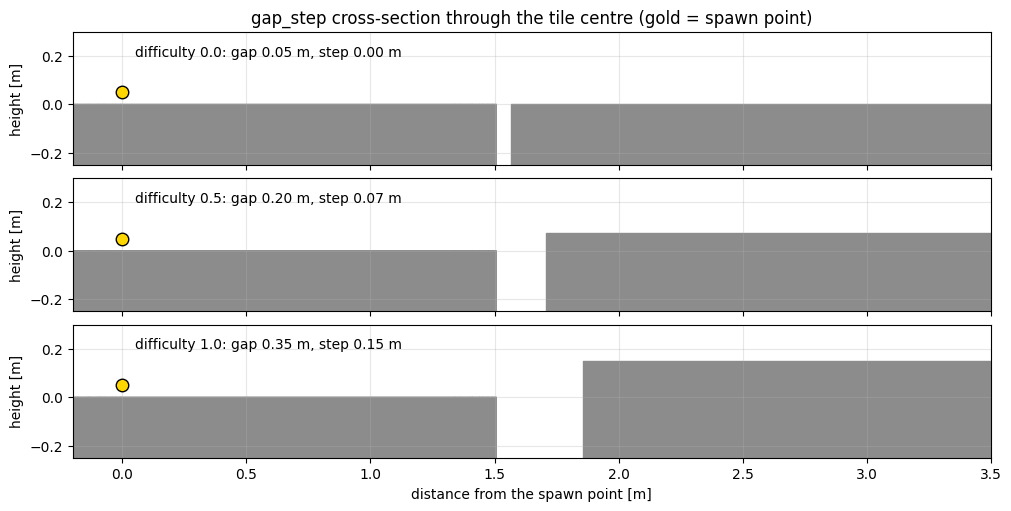

In [9]:
from go2_parkour.terrains import GapStepTerrainCfg, gap_step_terrain
import trimesh

difficulties = (0.0, 0.5, 1.0)
fig, axes = plt.subplots(len(difficulties), 1, figsize=(10, 5), sharex=True, sharey=True, layout="constrained")
for ax, difficulty in zip(axes, difficulties):
    cfg = GapStepTerrainCfg(size=(8.0, 8.0))
    meshes, origin = gap_step_terrain(difficulty, cfg)
    z, (x0, x1, y0, y1) = height_map(trimesh.util.concatenate(meshes), resolution=0.01)
    row = z[z.shape[0] // 2]  # the line through the tile centre
    x = np.linspace(x0, x1, len(row)) - origin[0]
    solid = np.isfinite(row)
    ax.fill_between(x, np.where(solid, row, -0.25), -0.25, where=solid, color="0.55", step="mid")  # ground in grey
    gap = cfg.gap_width_range[0] + difficulty * (cfg.gap_width_range[1] - cfg.gap_width_range[0])
    step = cfg.step_height_range[0] + difficulty * (cfg.step_height_range[1] - cfg.step_height_range[0])
    ax.text(0.05, 0.2, f"difficulty {difficulty}: gap {gap:.2f} m, step {step:.2f} m", fontsize=10)
    ax.plot(0, 0.05, "o", ms=9, color="gold", mec="black")  # the spawn point
    ax.set_ylabel("height [m]")
    ax.grid(alpha=0.3)
axes[0].set(xlim=(-0.2, 3.5), ylim=(-0.25, 0.3), title="gap_step cross-section through the tile centre (gold = spawn point)")
axes[-1].set_xlabel("distance from the spawn point [m]")
plt.show()

## 2.4 Which column is which type?

In the real grid there are 20 columns, shared out by `proportion`. The curriculum keeps each robot in its column
(its type) and only moves it up and down the rows. We will need this mapping later, so it lives in
`go2_parkour/evaluation.py` (Part 6) and replicates the generator's rule exactly:

In [10]:
from go2_parkour.evaluation import type_columns

for name, cols in type_columns(PARKOUR_TERRAINS_CFG).items():
    print(f"{name:9s} proportion {PARKOUR_TERRAINS_CFG.sub_terrains[name].proportion:4.2f} -> columns {cols}")

rough     proportion 0.10 -> columns [0, 1]
climb     proportion 0.25 -> columns [2, 3, 4, 5, 6]
drop      proportion 0.15 -> columns [7, 8, 9]
gap       proportion 0.25 -> columns [10, 11, 12, 13, 14]
gap_step  proportion 0.25 -> columns [15, 16, 17, 18, 19]


**Exercises:**
1. Make the hardest wall 40 cm (`pit_depth_range`) and rerun 2.3. Do you think the Go2 can climb it? (Its hips
   are about 30 cm high.) Keep a note: Part 6 will tell you.
2. Add a stairs column using `terrain_gen.MeshPyramidStairsTerrainCfg` (see `isaaclab/terrains/config/rough.py`).
   If you keep it, also re-run the `%%writefile` cell so the package file changes.

---
# Part 3 — Task code

## 3.1 Three new MDP terms

Every manager term in Isaac Lab is a plain function: it gets the environment (plus the `params` from its config)
and returns **one value per environment**. We need three:

1. **`height_scan_with_holes`** (observation): Isaac Lab's `height_scan`, but a ray that hits nothing reads as a
   1 m deep hole. *Why* this is needed is the main finding of Part 4. For now, compare it with the original:

In [11]:
from isaaclab.envs import mdp as isaaclab_mdp

print(inspect.getsource(isaaclab_mdp.height_scan))

def height_scan(env: ManagerBasedEnv, sensor_cfg: SceneEntityCfg, offset: float = 0.5) -> torch.Tensor:
    """Height scan from the given sensor w.r.t. the sensor's frame.

    The provided offset (Defaults to 0.5) is subtracted from the returned values.
    """
    sensor: RayCaster = env.scene.sensors[sensor_cfg.name]
    # height scan: height = sensor_height - hit_point_z - offset
    return sensor.data.pos_w.torch[:, 2].unsqueeze(1) - sensor.data.ray_hits_w.torch[..., 2] - offset



2. **`fell_into_gap`** (termination): the gaps have no floor, so a robot that misses a jump would fall forever and
   its episode would only end at the 20 s time-out: wasted samples, and no clear failure signal. We end the episode
   when the base is 0.5 m below the robot's spawn height.
3. **`feet_stumble`** (reward, negative weight): a foot that hits the *side* of a wall instead of stepping on top
   produces a mostly horizontal contact force. Counting such feet and penalizing them encourages lifting the feet
   high enough. (This term comes from ETH's `legged_gym`.)

In [13]:
%%writefile parkour/go2_parkour/mdp.py
"""Task-specific MDP terms for parkour: one termination and one reward, written as plain functions.

Isaac Lab calls each term with the environment as first argument (plus the `params` from its config) and
expects one value per environment back: a bool tensor (num_envs,) for terminations, a float tensor for rewards.
"""

from __future__ import annotations

from typing import TYPE_CHECKING

import torch

from isaaclab.managers import SceneEntityCfg

if TYPE_CHECKING:
    from isaaclab.envs import ManagerBasedRLEnv


def height_scan_with_holes(
    env: ManagerBasedRLEnv, sensor_cfg: SceneEntityCfg, offset: float = 0.5, miss_depth: float = 1.0
) -> torch.Tensor:
    """Height scan where a ray that hits nothing (a gap) reads as a ``miss_depth``-metre hole.

    Isaac Lab's ``height_scan`` computes ``sensor_height - hit_height - offset``. A ray that misses the terrain
    reports ``hit_height = +inf``, so the value becomes ``-inf`` and, after clipping, looks like a *wall* 1 m
    higher than the robot. Here a miss is replaced by a hit ``miss_depth`` below the reference level instead.
    Positive values = terrain lower than the robot, negative = higher.
    """
    sensor = env.scene.sensors[sensor_cfg.name]
    sensor_z = sensor.data.pos_w.torch[:, 2].unsqueeze(1)
    hit_z = sensor.data.ray_hits_w.torch[..., 2]
    hit_z = torch.where(torch.isfinite(hit_z), hit_z, sensor_z - offset - miss_depth)
    return sensor_z - hit_z - offset


def fell_into_gap(
    env: ManagerBasedRLEnv, depth: float = 0.5, asset_cfg: SceneEntityCfg = SceneEntityCfg("robot")
) -> torch.Tensor:
    """Terminate when the robot's base is more than ``depth`` metres below the height it spawned at.

    The gap terrains have no floor, so a robot that misses a jump would otherwise fall forever (and its episode
    would run until the time-out, teaching nothing). The env origin is the spawn point of the robot's current tile.
    """
    robot = env.scene[asset_cfg.name]
    return robot.data.root_pos_w.torch[:, 2] < env.scene.env_origins[:, 2] - depth


def feet_stumble(env: ManagerBasedRLEnv, sensor_cfg: SceneEntityCfg, ratio: float = 2.0) -> torch.Tensor:
    """Penalize feet that hit a vertical surface (a wall or box edge) instead of stepping on top of it.

    A foot "stumbles" when the horizontal part of its contact force is more than ``ratio`` times the vertical part.
    Returns the number of stumbling feet per environment (0..4).
    """
    contact_sensor = env.scene.sensors[sensor_cfg.name]
    forces = contact_sensor.data.net_normal_forces_w.torch[:, sensor_cfg.body_ids]  # (num_envs, num_feet, 3)
    horizontal = torch.linalg.norm(forces[..., :2], dim=-1)
    vertical = torch.abs(forces[..., 2])
    return torch.sum(horizontal > ratio * vertical, dim=1).float()

Overwriting parkour/go2_parkour/mdp.py


## 3.2 The environment config

`Go2ParkourEnvCfg` **inherits** the Go2 rough-terrain config and overrides only what changes (the table in Part 1).
Everything else (robot, PD gains, the other rewards, domain randomization, the curriculum term) is inherited.

In [14]:
%%writefile parkour/go2_parkour/env_cfg.py
"""The Go2 parkour environment: Isaac Lab's Go2 rough-terrain task with parkour terrain and two new MDP terms."""

from __future__ import annotations

import copy

from isaaclab.managers import RewardTermCfg as RewTerm
from isaaclab.managers import SceneEntityCfg
from isaaclab.managers import TerminationTermCfg as DoneTerm
from isaaclab.utils import configclass

from isaaclab_tasks.core.velocity.config.go2.rough_env_cfg import UnitreeGo2RoughEnvCfg

from . import mdp
from .terrains import PARKOUR_TERRAINS_CFG


@configclass
class Go2ParkourEnvCfg(UnitreeGo2RoughEnvCfg):
    """Everything not changed here (robot, observations incl. the height scan, actions, the other rewards,
    domain randomization, the terrain-level curriculum) is inherited from the Go2 rough-terrain task."""

    def __post_init__(self):
        super().__post_init__()  # builds the Go2 rough-terrain task

        # --- terrain: our parkour grid instead of the rough one; the curriculum orders rows by difficulty
        self.scene.terrain.terrain_generator = copy.deepcopy(PARKOUR_TERRAINS_CFG)
        self.scene.terrain.terrain_generator.curriculum = True
        self.scene.terrain.max_init_terrain_level = 3  # start on the 4 easiest levels

        # --- commands: mostly forward, so the robot runs *into* the obstacles around its spawn platform
        ranges = self.commands.base_velocity.ranges
        ranges.lin_vel_x = (0.3, 1.0)
        ranges.lin_vel_y = (-0.3, 0.3)

        # --- observations: gaps must look like holes, not walls (see mdp.height_scan_with_holes)
        self.observations.policy.height_scan.func = mdp.height_scan_with_holes

        # --- terminations: falling into a gap ends the episode
        self.terminations.fell_into_gap = DoneTerm(func=mdp.fell_into_gap, params={"depth": 0.5})

        # --- rewards: penalize feet hitting walls / box edges
        self.rewards.feet_stumble = RewTerm(
            func=mdp.feet_stumble,
            weight=-0.5,
            params={"sensor_cfg": SceneEntityCfg("contact_forces", body_names=".*_foot")},
        )

Overwriting parkour/go2_parkour/env_cfg.py


## 3.3 PPO settings, registration and packaging

The PPO settings inherit the Go2 rough-terrain ones; we only train longer and log to our own folder:

In [15]:
%%writefile parkour/go2_parkour/agents.py
"""PPO settings for the parkour task: the Go2 rough-terrain settings, with a longer training and its own log folder."""

from isaaclab.utils import configclass

from isaaclab_tasks.core.velocity.config.go2.agents.rsl_rl_ppo_cfg import UnitreeGo2RoughPPORunnerCfg


@configclass
class Go2ParkourPPORunnerCfg(UnitreeGo2RoughPPORunnerCfg):
    def __post_init__(self):
        super().__post_init__()
        self.experiment_name = "go2_parkour"  # runs are saved to logs/rsl_rl/go2_parkour/
        self.max_iterations = 3000

Overwriting parkour/go2_parkour/agents.py


**Registration** links a task name to the environment class, the env config and the agent config (as in notebook 1,
Part 6). It runs when the package is imported:

In [16]:
%%writefile parkour/go2_parkour/__init__.py
"""Go2 parkour task for Isaac Lab, built step by step in notebook 02.

Importing this package registers the task with gymnasium. The `isaaclab` command-line tool imports it
automatically through the `isaaclab.tasks` entry point declared in ../pyproject.toml.
"""

import gymnasium as gym

gym.register(
    id="Go2-Parkour",
    entry_point="isaaclab.envs:ManagerBasedRLEnv",
    disable_env_checker=True,
    kwargs={
        "env_cfg_entry_point": f"{__name__}.env_cfg:Go2ParkourEnvCfg",
        "rsl_rl_cfg_entry_point": f"{__name__}.agents:Go2ParkourPPORunnerCfg",
        "default_agent": "rsl_rl",
    },
)

Overwriting parkour/go2_parkour/__init__.py


**How does `isaaclab train --task Go2-Parkour` find a task that lives outside Isaac Lab?** Through a Python
*entry point*: `parkour/pyproject.toml` declares the package under the group `isaaclab.tasks`, and the `isaaclab`
command imports every package in that group at start-up. `run.sh` and `start_jupyter.sh` install the package
(editable, so your `%%writefile` changes are live). This is the official mechanism, also used by NVIDIA's own
external Isaac Lab projects.

In [17]:
print((ROOT / "parkour" / "pyproject.toml").read_text())

[project]
name = "go2-parkour"
version = "0.1.0"
description = "Go2 parkour task for Isaac Lab, built in notebook 02 of isaaclab-newton-tutorials"
requires-python = ">=3.11"

# This is how the `isaaclab` command-line tool finds tasks that live outside Isaac Lab:
# it imports every package listed under the "isaaclab.tasks" entry-point group.
[project.entry-points."isaaclab.tasks"]
go2_parkour = "go2_parkour"

[build-system]
requires = ["setuptools>=61"]
build-backend = "setuptools.build_meta"

[tool.setuptools]
packages = ["go2_parkour"]



In [18]:
reload_parkour()
# ask the real command-line tool (in a separate process) whether it sees our task
!cd {ROOT} && ./run.sh isaaclab list_envs 2>/dev/null | grep -E "Task Name|Parkour"

| S. No. | Task Name                                                                 | Entry Point                                                                                            | Config                                                                                                                       | RL Libraries                         |
|  149   | Go2-Parkour                                                               | isaaclab.envs:ManagerBasedRLEnv                                                                        | go2_parkour.env_cfg:Go2ParkourEnvCfg                                                                                         | rsl_rl                               |


---
# Part 4 — Look before you train

Now we build the real environment and **look**. We place six robots by hand, at the hardest level, each 0.5 m in
front of a different obstacle, and give each one a camera:

| Robot | Where | What we check |
|---|---|---|
| 0 | in a pit, before the wall | what the height scan shows for a wall |
| 1 | before a gap | ... for a gap |
| 2 | on a box, before the edge | ... for a drop |
| 3 | before a gap onto a step | ... for both |
| 4 | dropped *lengthwise* into a gap | `fell_into_gap` fires |
| 5 | before a *low* wall (level 2), pushed into it | `feet_stumble` counts feet hitting the wall |

The robots hold their default pose (zero actions); we only teleport and push them. Placing a robot means writing
its root pose: position + orientation as a quaternion in (x, y, z, **w**) order.

**Predict first:** robot 1 stands in front of a gap. Isaac Lab's `height_scan` is `sensor height - hit height - 0.5`.
What is the hit height of a ray that hits nothing, and what value does the robot then observe there?

This cell builds the environment (the full parkour grid) and runs all checks: about a minute.

In [28]:
import isaaclab.sim as sim_utils
from isaaclab.app import launch_simulation
from isaaclab.envs import ManagerBasedRLEnv
from isaaclab.managers import SceneEntityCfg
from isaaclab.sensors import CameraCfg
from isaaclab_newton.renderers import NewtonWarpRendererCfg
from isaaclab_tasks.utils.hydra import resolve_presets
from isaaclab_tasks.utils.presets import MultiBackendRendererCfg

reload_parkour()
from go2_parkour import mdp as parkour_mdp
from go2_parkour.env_cfg import Go2ParkourEnvCfg


def camera_cfg(width=320, height=240):
    return CameraCfg(
        prim_path="{ENV_REGEX_NS}/Camera", data_types=["rgb"], width=width, height=height,
        spawn=sim_utils.PinholeCameraCfg(focal_length=14.0, horizontal_aperture=20.955, clipping_range=(0.1, 100.0)),
        renderer_cfg=MultiBackendRendererCfg(newton_renderer=NewtonWarpRendererCfg(enable_shadows=True)),
    )


# (obstacle type, level, offset from the tile origin [m], yaw [deg], label)
CASES = [
    ("climb", 9, (1.0, 0.0, 0.0), 0, "0: wall ahead"),
    ("gap", 9, (1.0, 0.0, 0.0), 0, "1: gap ahead"),
    ("drop", 9, (1.0, 0.0, 0.0), 0, "2: drop ahead"),
    ("gap_step", 9, (1.0, 0.0, 0.0), 0, "3: gap + step ahead"),
    ("gap", 9, (1.72, 0.0, 0.45), 90, "4: dropped into a gap"),
    ("climb", 2, (1.0, 0.0, 0.0), 0, "5: low wall ahead"),
]
n = len(CASES)

cfg = Go2ParkourEnvCfg()
cfg.scene.camera = camera_cfg()
cfg = resolve_presets(cfg, selected=("newton_mjwarp", "newton_renderer"))
cfg.scene.num_envs = n
cfg.sim.visualizer_cfgs = []
cfg.events.push_robot = None  # no random pushes during the checks
columns = type_columns(cfg.scene.terrain.terrain_generator)

with quiet_simulation(), launch_simulation(cfg, SIM_ARGS):
    env = ManagerBasedRLEnv(cfg)
    try:
        robot, terrain, camera = env.scene["robot"], env.scene.terrain, env.scene["camera"]
        dev = env.device
        info = {"observation size": env.observation_manager.group_obs_dim["policy"],
                "terminations": env.termination_manager.active_terms,
                "new reward term": [t for t in env.reward_manager.active_terms if t == "feet_stumble"]}
        env.reset()
        ids = torch.arange(n, device=dev)

        def place():
            # put each robot on its tile (type column, level row) at its offset and heading
            terrain.terrain_levels[:] = torch.tensor([c[1] for c in CASES], device=dev)
            terrain.terrain_types[:] = torch.tensor([columns[c[0]][0] for c in CASES], device=dev)
            terrain.env_origins[:] = terrain.terrain_origins[terrain.terrain_levels, terrain.terrain_types]
            pose = robot.data.default_root_pose.torch.clone()
            pose[:, :3] = terrain.env_origins + torch.tensor([c[2] for c in CASES], device=dev) + torch.tensor([0, 0, 0.4], device=dev)
            yaw = torch.tensor([math.radians(c[3]) for c in CASES], device=dev)
            pose[:, 3:] = torch.stack([0 * yaw, 0 * yaw, torch.sin(yaw / 2), torch.cos(yaw / 2)], dim=1)  # (x, y, z, w)
            robot.write_root_pose_to_sim_index(root_pose=pose, env_ids=ids)
            robot.write_root_velocity_to_sim_index(root_velocity=torch.zeros(n, 6, device=dev), env_ids=ids)

        zero_actions = torch.zeros(n, env.action_manager.total_action_dim, device=dev)
        place()

        # --- check A: terminations over 0.8 s (env.step resets an env that terminated, so we ask the
        #     termination manager inside the loop instead of looking at the robot afterwards)
        first_step = {"fell_into_gap": [None] * n, "base_contact": [None] * n}
        for step in range(40):
            env.step(zero_actions)
            for term in first_step:
                fired = env.termination_manager.get_term(term)
                for i in range(n):
                    if fired[i] and first_step[term][i] is None:
                        first_step[term][i] = step

        # --- check B: push robot 5 into its low wall for 1 s, record feet_stumble
        feet = SceneEntityCfg("contact_forces", body_names=".*_foot")
        feet.resolve(env.scene)
        stumble = []
        for step in range(50):
            push = torch.zeros(1, 6, device=dev)
            push[0, 0] = 0.8  # 0.8 m/s forward
            robot.write_root_velocity_to_sim_index(root_velocity=push, env_ids=ids[5:6])
            env.step(zero_actions)
            stumble.append(parkour_mdp.feet_stumble(env, feet).cpu().numpy())
        stumble = np.array(stumble)

        # --- check C: what each robot perceives, standing still in front of its obstacle
        place()
        for _ in range(10):
            env.step(zero_actions)
        scanner = SceneEntityCfg("height_scanner")
        scan_isaaclab = isaaclab_mdp.height_scan(env, scanner).clamp(-1, 1).cpu().numpy()  # as clipped in the obs
        scan_ours = parkour_mdp.height_scan_with_holes(env, scanner).clamp(-1, 1).cpu().numpy()
        misses = torch.isinf(env.scene["height_scanner"].data.ray_hits_w.torch[..., 2]).sum(1).tolist()
        base = robot.data.root_pos_w.torch.clone()
        look = base.clone()
        look[:, 2] = terrain.env_origins[:, 2] + 0.1
        camera.set_world_poses_from_view(eyes=look + torch.tensor([-1.4, -1.4, 1.0], device=dev),
                                         targets=look + torch.tensor([0.6, 0.0, 0.0], device=dev))
        for _ in range(3):
            env.step(zero_actions)
        images = camera.data.output["rgb"].torch[..., :3].cpu().numpy()
    finally:
        env.close()

for k, v in info.items():
    print(f"{k:17s}: {v}")
print("rays that hit nothing, per robot:", misses)

observation size : (235,)
terminations     : ['time_out', 'base_contact', 'fell_into_gap']
new reward term  : ['feet_stumble']
rays that hit nothing, per robot: [0, 33, 0, 33, 85, 0]


### What the robots perceive

Below each camera image: the height scan as an image (17 points along x = forward, 11 along y), shown as
*terrain height relative to the ground under the robot* (red = higher, blue = lower). Top row of scans: Isaac Lab's
`height_scan`. Bottom row: ours.

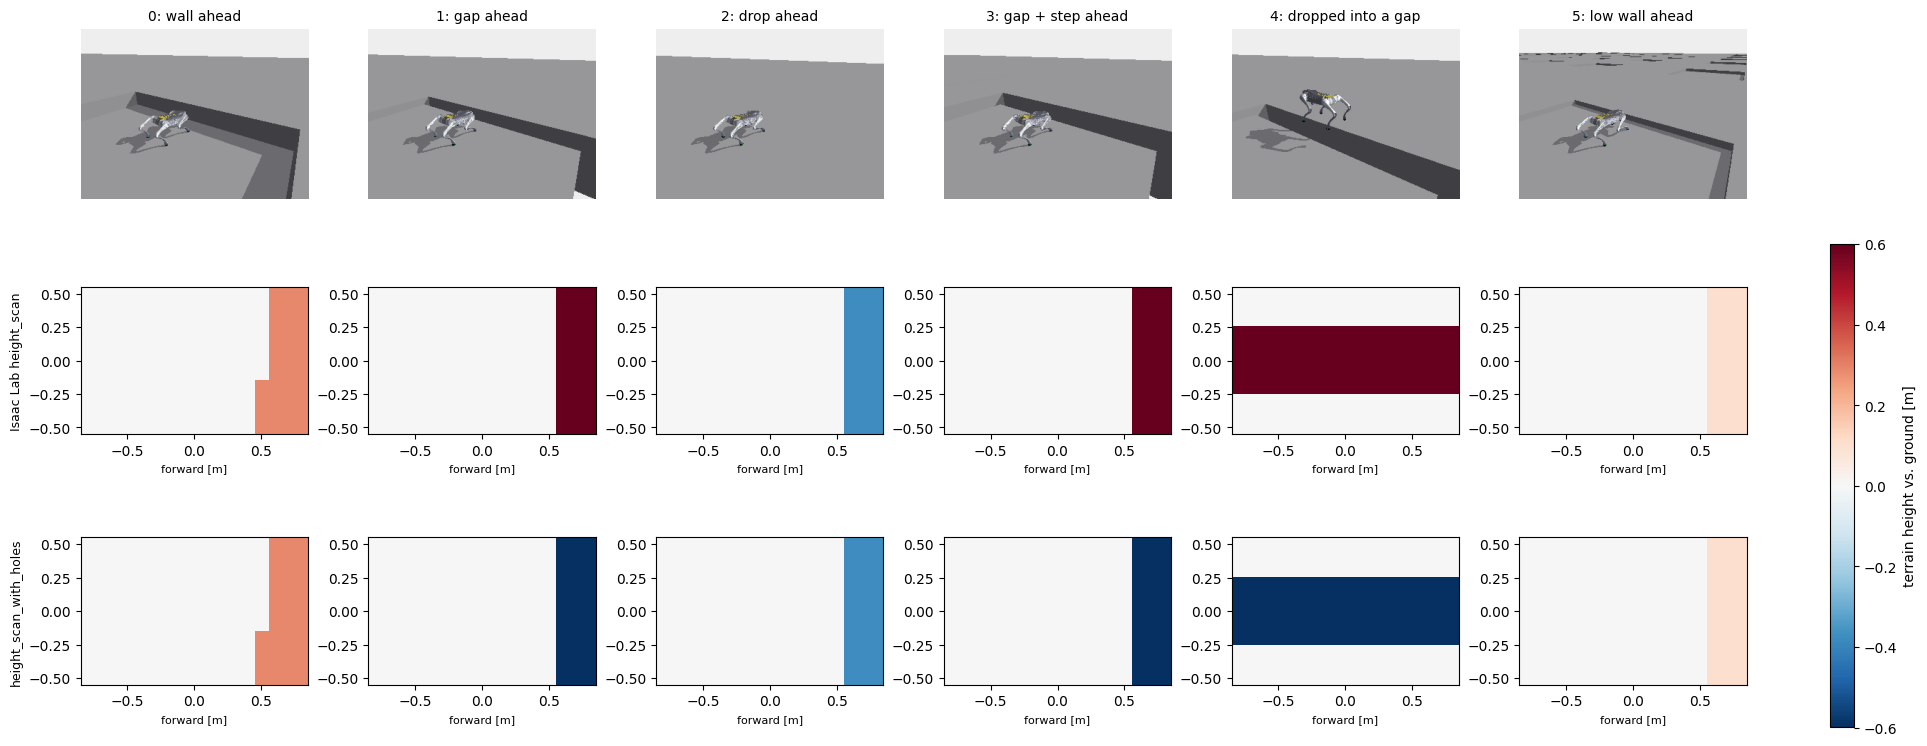

In [29]:
def scan_image(scan):
    grid = scan.reshape(11, 17)  # rays are ordered x-major: 17 along x (forward), 11 along y
    return -(grid - np.median(grid))  # height relative to the ground under the robot


fig, axes = plt.subplots(3, n, figsize=(3.2 * n, 7.5), layout="constrained")
for i, case in enumerate(CASES):
    axes[0, i].imshow(images[i])
    axes[0, i].set_title(case[4], fontsize=10)
    axes[0, i].axis("off")
    for row, (scan, name) in enumerate([(scan_isaaclab, "Isaac Lab height_scan"), (scan_ours, "height_scan_with_holes")], 1):
        im = axes[row, i].imshow(scan_image(scan[i]), origin="lower", cmap="RdBu_r", vmin=-0.6, vmax=0.6,
                                 extent=(-0.85, 0.85, -0.55, 0.55))
        axes[row, i].set_xlabel("forward [m]", fontsize=8)
        if i == 0:
            axes[row, i].set_ylabel(name, fontsize=9)
fig.colorbar(im, ax=axes[1:, :].ravel().tolist(), fraction=0.02, label="terrain height vs. ground [m]")
plt.show()

**What went wrong with Isaac Lab's `height_scan`?** A ray that hits nothing reports a hit height of `+inf`. The
observation becomes `sensor - inf - 0.5 = -inf`, which the observation manager clips to **-1**: the value for
terrain **1 m higher** than the robot. So with the default term, **a gap looks like a tall wall** (robots 1, 3, 4:
red where the gap is). A policy could still learn to treat "walls" as gaps, but it would have to *unlearn* a
contradiction, and real walls and gaps would look alike. With our term the gap is dark blue: a deep hole.

This is not a bug you would ever find from a reward curve. Looking at what the robot perceives, before training,
is how you find it.

### Did the new terms fire?

step at which each termination first fired (None = never), per robot:
  fell_into_gap : [None, None, None, None, 26, None]
  base_contact  : [None, None, None, None, None, None]

max feet_stumble per robot while robot 5 is pushed into its wall: [0.0, 0.0, 0.0, 0.0, 0.0, 2.0]


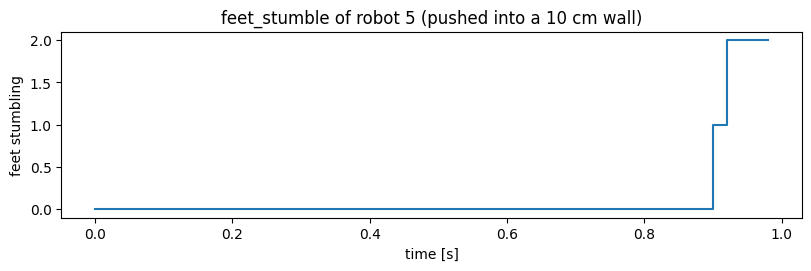

In [30]:
print("step at which each termination first fired (None = never), per robot:")
for term, steps in first_step.items():
    print(f"  {term:14s}: {steps}")
print("\nmax feet_stumble per robot while robot 5 is pushed into its wall:", stumble.max(axis=0).tolist())

fig, ax = plt.subplots(figsize=(8, 2.6), layout="constrained")
ax.plot(np.arange(len(stumble)) * cfg.sim.dt * cfg.decimation, stumble[:, 5], drawstyle="steps-post")
ax.set(xlabel="time [s]", ylabel="feet stumbling", title="feet_stumble of robot 5 (pushed into a 10 cm wall)")
plt.show()

What you should see:

- `fell_into_gap` fires only for robot 4 (dropped lengthwise into the gap; the Go2 is narrower than the gap), and
  `base_contact` for nobody. If you drop the robot *across* the gap (yaw 0), it gets wedged instead and its trunk
  touches the edge: then `base_contact` ends the episode. Try it (change robot 4's yaw to 0 in `CASES`).
- `feet_stumble` is non-zero only for robot 5, while its feet are pushed against the wall.

**Exercise:** check the third new piece, the forward-biased commands, by printing
`env.command_manager.get_command("base_velocity")` inside the cell (inside the `try`). Are all `vx` in [0.3, 1.0]?

---
# Part 5 — Curriculum and a sanity training

## 5.1 How the terrain curriculum works

Without a curriculum, most robots would start in front of obstacles they cannot possibly clear: almost every
episode fails, the reward carries almost no information about *how* to improve, and training stalls (often in
the standing-still optimum from notebook 1). The **terrain-level curriculum** gives each robot an obstacle just
at the edge of what it can do:

In [31]:
from isaaclab_tasks.core.velocity.mdp import curriculums

print(inspect.getsource(curriculums.terrain_levels_vel))

def terrain_levels_vel(
    env: ManagerBasedRLEnv, env_ids: Sequence[int], asset_cfg: SceneEntityCfg = SceneEntityCfg("robot")
) -> torch.Tensor:
    """Curriculum based on the distance the robot walked when commanded to move at a desired velocity.

    This term is used to increase the difficulty of the terrain when the robot walks far enough and decrease the
    difficulty when the robot walks less than half of the distance required by the commanded velocity.

    .. note::
        It is only possible to use this term with the terrain type ``generator``. For further information
        on different terrain types, check the :class:`isaaclab.terrains.TerrainImporter` class.

    Returns:
        The mean terrain level for the given environment ids.
    """
    # extract the used quantities (to enable type-hinting)
    asset: Articulation = env.scene[asset_cfg.name]
    terrain: TerrainImporter = env.scene.terrain
    command = env.command_manager.get_command("base_velocity")
    # com

At every reset of a robot:

- walked more than **half a tile** (4 m) from its spawn point -> **one level up** (it got past the obstacle),
- walked less than **half the distance its command asked for** -> **one level down**,
- a robot that solves the last level is sent to a **random** level (so the hard levels don't take over the batch).

Robots start on levels 0-3 (`max_init_terrain_level = 3`). So the most informative single number during
training is the **mean terrain level** (`Curriculum/terrain_levels`): if it rises, the robots are learning parkour.

## 5.2 Sanity training (about 2 minutes)

Before the long run, train for a few iterations **in the notebook** and check that nothing is broken:
the episode length grows, terminations are sensible (`fell_into_gap` and `base_contact` both occur, but not in
every episode), and the curriculum moves. This is the same `train()` helper as in notebook 1, with live plots of
the training curves (blue = read from TensorBoard every iteration).

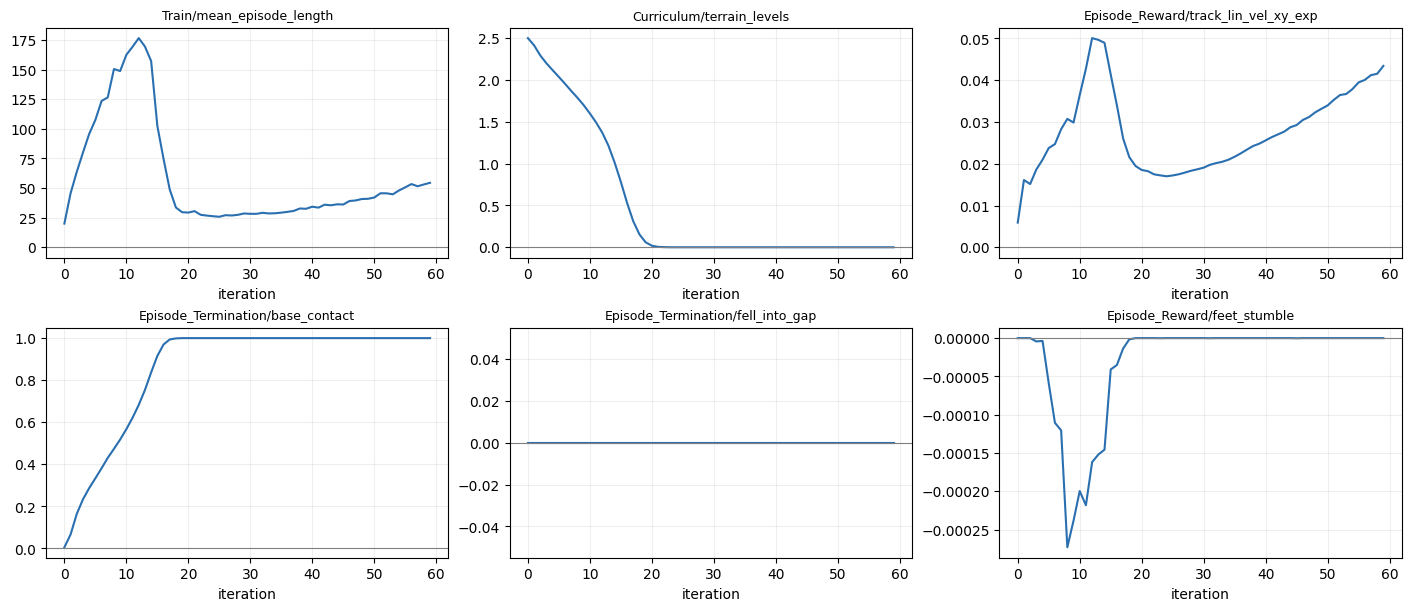

run saved in logs/go2_parkour_sanity/2026-11-19_12-36-06


In [32]:
from datetime import datetime

from rsl_rl.runners import OnPolicyRunner
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

from isaaclab.utils import to_dict
from isaaclab_rl.rsl_rl import RslRlVecEnvWrapper


def plot_logged_tags(axes, run_dir, writer, tags):
    writer.flush()
    acc = EventAccumulator(str(run_dir), size_guidance={"scalars": 0})
    acc.Reload()
    available = set(acc.Tags()["scalars"])
    for ax, tag in zip(axes, tags):
        ax.clear()
        if tag in available:
            events = acc.Scalars(tag)
            ax.plot([e.step for e in events], [e.value for e in events], color="#2a6fb0", lw=1.5)
        ax.axhline(0.0, color="gray", lw=0.8)
        ax.set(title=tag, xlabel="iteration")
        ax.title.set_fontsize(9)
        ax.grid(alpha=0.2)


def train(env_cfg, agent_cfg, chunks=10, log_tags=()):
    # Train with PPO (RSL-RL), redrawing the TensorBoard curves after each chunk. Returns the run folder.
    run_dir = ROOT / "logs" / agent_cfg.experiment_name / f"{datetime.now():%Y-%m-%d_%H-%M-%S}"
    chunk = max(1, agent_cfg.max_iterations // chunks)
    ncols = 3
    fig, axes = plt.subplots(-(-len(log_tags) // ncols), ncols, figsize=(14, 3.0 * -(-len(log_tags) // ncols)),
                             layout="constrained", squeeze=False)
    axes = axes.ravel()
    for ax in axes[len(log_tags):]:
        ax.axis("off")
    handle = display(fig, display_id=True)
    plt.close(fig)
    env_cfg = resolve_presets(copy.deepcopy(env_cfg), selected=("newton_mjwarp",))
    env_cfg.seed = agent_cfg.seed
    env_cfg.sim.visualizer_cfgs = []
    with quiet_simulation(), launch_simulation(env_cfg, SIM_ARGS):
        env = RslRlVecEnvWrapper(ManagerBasedRLEnv(env_cfg), clip_actions=agent_cfg.clip_actions)
        try:
            runner = OnPolicyRunner(env, to_dict(agent_cfg), log_dir=str(run_dir), device=agent_cfg.device)
            for i in range(agent_cfg.max_iterations // chunk):
                runner.learn(num_learning_iterations=chunk, init_at_random_ep_len=(i == 0))
                runner.current_learning_iteration += 1
                plot_logged_tags(axes, run_dir, runner.logger.writer, log_tags)
                handle.update(fig)
        finally:
            env.close()
    return run_dir


reload_parkour()
from go2_parkour.agents import Go2ParkourPPORunnerCfg

sanity_agent = Go2ParkourPPORunnerCfg()
sanity_agent.experiment_name = "go2_parkour_sanity"
sanity_agent.max_iterations = 60  # the real training uses 3000
SANITY_TAGS = [
    "Train/mean_episode_length",
    "Curriculum/terrain_levels",
    "Episode_Reward/track_lin_vel_xy_exp",
    "Episode_Termination/base_contact",
    "Episode_Termination/fell_into_gap",
    "Episode_Reward/feet_stumble",
]
sanity_run = train(Go2ParkourEnvCfg(), sanity_agent, chunks=6, log_tags=SANITY_TAGS)
print("run saved in", sanity_run.relative_to(ROOT))

**How to read this** (after only a few dozen iterations, nothing should look *good* yet; we only check it's sane):

- **Episode length** (in steps, 50 per second) should grow: the robots first learn not to fall over.
- **Terrain levels** starts around 2 (robots spread over levels 0-3). Early on it *drops*: failing robots are
  demoted to easy terrain, which is exactly the curriculum doing its job. In the long run it must rise.
- **Terminations** are the *fraction of episodes* that ended for each reason. Early on, more and more episodes end
  with a trunk contact (robots that used to time out standing still now move and fall); this fraction should come
  down later. `fell_into_gap` can stay at 0 for a while: on the low levels the gaps are narrower than the robot.
- **feet_stumble** is negative (it's a penalty): feet are hitting walls.

If any of these are flat zeros or NaNs, something is wrong with the task: fix it now, not after an hour.

---
# Part 6 — Evaluation: what does "it works" mean?

The training reward mixes a dozen terms, and the curriculum changes the terrain under it, so its value is hard to
interpret. For parkour the question is simple: **which obstacles, up to which size, can the robot clear?**

The evaluation puts robots on **every tile** of a grid with one column per obstacle type and one row per level,
facing forward, commands 0.8 m/s straight ahead, and counts a success when a robot gets **3 m** from its spawn
point (past every obstacle) before its episode ends. The result is a success-rate map.

In [33]:
%%writefile parkour/go2_parkour/evaluation.py
"""Evaluate a parkour policy: success rate for every obstacle type x difficulty level.

Robots are placed on every tile of a terrain grid with one column per obstacle type and one row per
difficulty level, all facing +x, and commanded to walk forward. A robot succeeds if it gets
``success_distance`` metres away from its spawn point (past every obstacle) without its episode ending.
"""

from __future__ import annotations

import numpy as np
import torch


def type_columns(gen_cfg) -> dict[str, list[int]]:
    """Which grid columns hold which obstacle type, exactly as the curriculum terrain generator assigns them."""
    names = list(gen_cfg.sub_terrains)
    p = np.array([s.proportion for s in gen_cfg.sub_terrains.values()], dtype=float)
    cum = np.cumsum(p / p.sum())
    cols = {n: [] for n in names}
    for c in range(gen_cfg.num_cols):
        cols[names[int(np.min(np.where(c / gen_cfg.num_cols + 0.001 < cum)[0]))]].append(c)
    return cols


def obstacle_size(sub_cfg, difficulty: float) -> str:
    """Human-readable obstacle size of a sub-terrain at a difficulty, e.g. 'gap 0.27 m'."""
    parts = []
    for field, label in (("pit_depth_range", "wall"), ("box_height_range", "drop"), ("gap_width_range", "gap"),
                         ("step_height_range", "step")):
        rng = getattr(sub_cfg, field, None)
        if rng is not None:
            parts.append(f"{label} {rng[0] + difficulty * (rng[1] - rng[0]):.2f}")
    return " + ".join(parts) if parts else "-"


def make_eval_env_cfg(robots_per_tile: int = 8, seconds: float = 8.0, forward_speed: float = 0.8):
    """The parkour env config, changed for evaluation: one column per type, fixed forward command, no pushes."""
    from isaaclab_tasks.utils.hydra import resolve_presets

    from .env_cfg import Go2ParkourEnvCfg

    cfg = Go2ParkourEnvCfg()
    gen = cfg.scene.terrain.terrain_generator
    gen.num_cols = len(gen.sub_terrains)
    for sub in gen.sub_terrains.values():
        sub.proportion = 1.0  # equal proportions -> exactly one column per type
    cfg.curriculum.terrain_levels = None  # we choose the tiles ourselves...
    gen.curriculum = True  # ...but keep rows sorted by difficulty
    cfg.scene.num_envs = gen.num_rows * gen.num_cols * robots_per_tile
    cfg.episode_length_s = seconds + 5.0
    cmd = cfg.commands.base_velocity
    cmd.heading_command, cmd.rel_standing_envs, cmd.resampling_time_range = False, 0.0, (1.0e6, 1.0e6)
    cmd.ranges.lin_vel_x = (forward_speed, forward_speed)
    cmd.ranges.lin_vel_y = (0.0, 0.0)
    cmd.ranges.ang_vel_z = (0.0, 0.0)
    cfg.events.push_robot = None
    cfg.events.base_external_force_torque = None
    cfg.events.reset_base.params["pose_range"] = {"x": (-0.2, 0.2), "y": (-0.2, 0.2), "yaw": (0.0, 0.0)}
    cfg.events.reset_base.params["velocity_range"] = {}
    cfg.sim.visualizer_cfgs = []
    return resolve_presets(cfg, selected=("newton_mjwarp",))


def evaluate(checkpoint: str, robots_per_tile: int = 8, seconds: float = 8.0, success_distance: float = 3.0,
             forward_speed: float = 0.8) -> dict:
    """Run the policy on every (type, level) tile. Returns success rates (types x levels) and labels.

    Must be called when no other simulation is running; it launches and closes its own.
    """
    from rsl_rl.runners import OnPolicyRunner

    from isaaclab.app import launch_simulation
    from isaaclab.envs import ManagerBasedRLEnv
    from isaaclab.utils import to_dict
    from isaaclab_rl.rsl_rl import RslRlVecEnvWrapper

    from .agents import Go2ParkourPPORunnerCfg

    cfg = make_eval_env_cfg(robots_per_tile, seconds, forward_speed)
    gen = cfg.scene.terrain.terrain_generator
    names, n_levels = list(gen.sub_terrains), gen.num_rows
    agent_cfg = Go2ParkourPPORunnerCfg()
    with launch_simulation(cfg, {"visualizer": None, "visualizer_explicit": True}):
        env = RslRlVecEnvWrapper(ManagerBasedRLEnv(cfg), clip_actions=agent_cfg.clip_actions)
        base = env.unwrapped
        try:
            runner = OnPolicyRunner(env, to_dict(agent_cfg), log_dir=None, device=agent_cfg.device)
            runner.load(str(checkpoint))
            policy = runner.get_inference_policy(device=base.device)
            # put robots_per_tile robots on every tile
            terrain, robot = base.scene.terrain, base.scene["robot"]
            n = base.num_envs
            tile = torch.arange(n, device=base.device) // robots_per_tile
            terrain.terrain_levels[:] = tile % n_levels
            terrain.terrain_types[:] = tile // n_levels
            terrain.env_origins[:] = terrain.terrain_origins[terrain.terrain_levels, terrain.terrain_types]
            obs, _ = env.reset()
            done = torch.zeros(n, dtype=torch.bool, device=base.device)  # result decided
            success = torch.zeros(n, dtype=torch.bool, device=base.device)
            with torch.inference_mode():
                for _ in range(int(seconds / base.step_dt)):
                    obs, _, dones, _ = env.step(policy(obs))
                    # an episode that ended this step is a failure (unless it already succeeded)
                    done |= dones.bool()
                    dist = torch.linalg.norm(robot.data.root_pos_w.torch[:, :2] - base.scene.env_origins[:, :2], dim=1)
                    reached = (dist > success_distance) & ~done
                    success |= reached
                    done |= reached
            rate = success.float().view(len(names), n_levels, robots_per_tile).mean(-1).cpu().numpy()
        finally:
            env.close()
    sizes = [[obstacle_size(gen.sub_terrains[t], (lvl + 0.5) / n_levels) for lvl in range(n_levels)] for t in names]
    return {"success": rate, "types": names, "sizes": sizes, "checkpoint": str(checkpoint)}


def plot_success(result: dict, ax=None):
    """Heat map of success rate: rows = obstacle types, columns = difficulty levels, labelled with obstacle sizes."""
    import matplotlib.pyplot as plt

    rate = result["success"]
    if ax is None:
        _, ax = plt.subplots(figsize=(1.1 * rate.shape[1] + 2, 0.7 * rate.shape[0] + 1.5), layout="constrained")
    im = ax.imshow(rate, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    for i in range(rate.shape[0]):
        for j in range(rate.shape[1]):
            ax.text(j, i, f"{rate[i, j]:.0%}\n{result['sizes'][i][j]}", ha="center", va="center", fontsize=6.5)
    ax.set_yticks(range(rate.shape[0]), result["types"])
    ax.set_xticks(range(rate.shape[1]), [f"level {j}" for j in range(rate.shape[1])], fontsize=8)
    ax.set_title("Success rate per obstacle type and difficulty (sizes in m)")
    plt.colorbar(im, ax=ax, fraction=0.02)
    return ax

Overwriting parkour/go2_parkour/evaluation.py


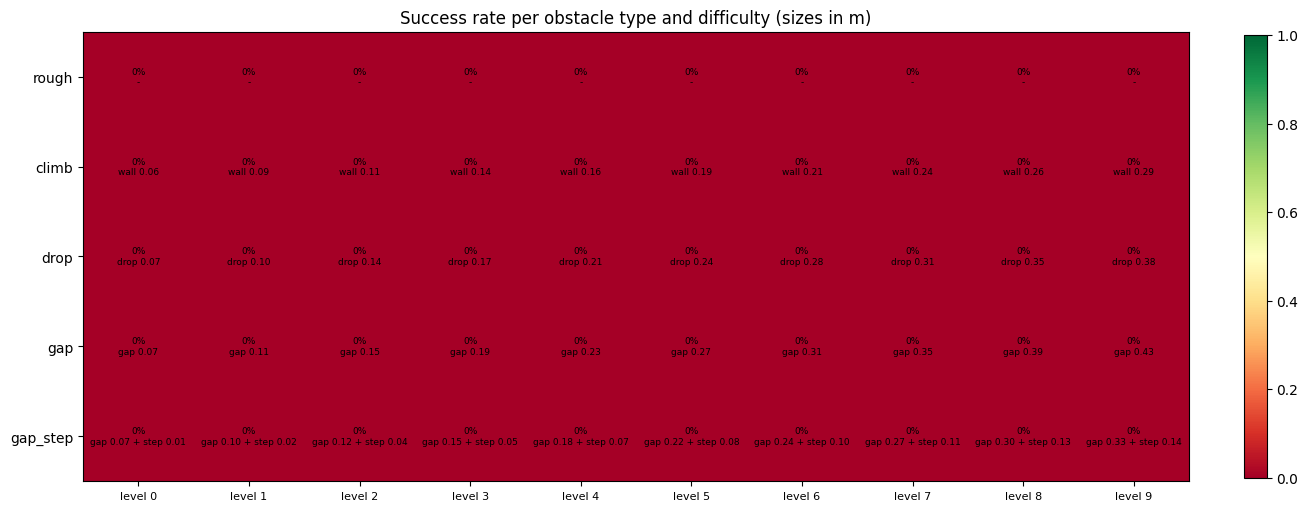

model_59.pt: mean success 0%


In [34]:
reload_parkour()
from go2_parkour.evaluation import evaluate, plot_success

sanity_checkpoint = max(sanity_run.glob("model_*.pt"), key=lambda p: int(p.stem.split("_")[1]))
with quiet_simulation():
    result = evaluate(sanity_checkpoint, robots_per_tile=4)
plot_success(result)
plt.show()
print(f"{sanity_checkpoint.name}: mean success {result['success'].mean():.0%}")

After a minute of training this map is (nearly) all red, and that is fine: it shows the evaluation works and gives
you the baseline. After the real training, this map is the result you show: it tells you, per obstacle, the size
up to which the policy is reliable. It's also the right tool to **compare** two trainings (e.g. with and without
`feet_stumble`): same robots, same tiles, one number per cell.

From the terminal, the same evaluation runs with `scripts/evaluate_parkour.py` (Part 7).

---
# Part 7 — The real training (terminal, about 1 hour)

Open a terminal in the repository folder and run:

```bash
./run.sh isaaclab train --rl_library rsl_rl --task Go2-Parkour
```

3000 iterations of 4096 robots: about **1 hour** on an RTX 5070 Laptop GPU (1.2 s per iteration), saved in
`logs/rsl_rl/go2_parkour/<date_time>/`. Training can be stopped with Ctrl+C and continued later from the newest
checkpoint by adding `--checkpoint latest` to the same command.

**Watch it** in a second terminal with TensorBoard (`http://localhost:6006`):

```bash
./run.sh tensorboard --logdir logs/rsl_rl/go2_parkour
```

The curve to watch is **`Curriculum/terrain_levels`**: it should rise. It can never reach 9, because robots that
solve the last level are sent to a random level; when it flattens, the policy has learned what it can with this
setup. Also watch the termination fractions and the per-term rewards as in Part 5.

**Evaluate** the trained policy (success map saved next to the checkpoint):

```bash
./run.sh python scripts/evaluate_parkour.py --checkpoint logs/rsl_rl/go2_parkour
```

**Drive it** with your keyboard (the same script as for notebook 1; the play mode shows a 5x5 grid of random obstacles):

```bash
./run.sh python scripts/drive_policy.py --task Go2-Parkour --checkpoint logs/rsl_rl/go2_parkour
```

**What a short run already shows** (a 300-iteration test run of this exact task, ~7 min): the policy cleared
rough ground (60-100 %), drops up to level 2 and the smallest gaps, but **no wall, not even the 6 cm one**. Watching
the robots showed why: they walk up to the wall and step up with the **front legs**, then stop with the **hind legs
stuck at the edge**. Getting the hind legs up is the skill the long training has to find: watch the `climb` row of
your success map.

**If the robots don't get past the low levels**, typical things to try, one at a time, compared with Part 6:

- the obstacle ranges are too hard: shrink the hardest wall/gap (Part 2) so the top levels are reachable,
- the base-height penalty (`base_height_l2`, weight -30) fights crouching and jumping: reduce it,
- `feet_air_time` is tiny (0.01): a higher weight rewards longer steps, which helps clearing obstacles,
- train longer (`--max_iterations 5000`).

---
# Part 8 — Recap and interview questions

**What you built:** a parkour task in its own package: custom terrain, an observation fix, a new termination and
reward, the task registered with Isaac Lab's CLI, every piece checked in simulation before training, a sanity
training, and a success-rate evaluation.

1. **Why does a parkour policy need a curriculum?** Without it most robots face obstacles they can't clear,
   nearly every episode fails the same way, and the reward gives little signal about how to improve. The terrain
   curriculum keeps each robot at the edge of its ability: promoted after success, demoted after failure.
2. **What does your policy perceive?** Proprioception (base velocities, gravity direction, joint positions and
   velocities, last action), the velocity command, and a 187-point height scan (1.6 m x 1.0 m grid, 10 cm spacing)
   around the robot, aligned with its heading.
3. **Tell me about a bug you found.** Isaac Lab's height scan turns rays that hit nothing into the value for a
   wall 1 m high, so gaps looked like walls. Found by visualizing the observation before training; fixed with an
   observation term that reads misses as deep holes.
4. **Why terminate when falling into a gap instead of penalizing it?** A floorless gap means the robot would fall
   until the time-out: wasted samples and a delayed, diluted failure signal. Terminating gives an immediate,
   unambiguous outcome (and loses all future reward, which is itself the penalty).
5. **How do you evaluate a parkour policy?** Success rate per obstacle type and size from fixed start states with
   a fixed command, not training reward (which mixes many terms and changes with the curriculum).
6. **How does Isaac Lab find a task in your own package?** The package registers its tasks with gymnasium when
   imported, and declares itself under the `isaaclab.tasks` entry-point group, which the CLI imports.
7. **How would this go to a real robot?** A real Go2 has no perfect height scan: either build an elevation map
   from depth sensors (and train with noise and delays on the scan), or train a *student* policy that uses depth
   images, distilled from this *teacher* policy (Isaac Lab has a `DistillationRunner` for this). Plus the usual
   sim-to-real tools: domain randomization of friction, mass, motor strength, latency.
8. **Why is the height scanner placed 20 m above the robot and only yaw-aligned?** The rays start high so they
   always start above the terrain; yaw alignment keeps the grid level (pointing forward) even when the body
   pitches or rolls, so the scan describes the terrain, not the robot's tilt.

**Next steps:** run the training (Part 7), evaluate it, record a video, and then improve one thing at a time,
comparing success maps.